# XGBoost hybrid: performance on the eval year

An analysis of the shipped XGBoost hybrid (`models.xgboost_model`, `docs/xgboost_model.md`) on the
held-out eval year, 2025-10-20 → 2026-10-20: 1,448 forecast runs, one every 6 hours, each 72
hours long. The model was selected and fitted on the training years only. The eval year was scored
once by `python -m training.xgboost_model evaluate`; this notebook breaks that score down.

**The model:**

    forecast(k) = linear(k) + trees(lead k, last speed, recurrence means, linear(k) − last, 25 regressors)

- **linear(k)** is the shipped linear model (`linear_model.ipynb`), embedded in the hybrid's asset.
- **The trees** are 100 boosted trees of depth 2, pooled over all leads and trained on hourly forecast times with per-run TIMSE weights.
- **Missing regressors** take each split's learned default branch, except the three never missing in training, which take their training medians.

**This is the tamed hybrid.** A first analysis of the selected hybrid found:
- **One rule dominated:** 15 of its 25 trees split first on the 5-day M-flare count at ≥ 48, a condition met only in May and August 2024.
- **It fired once in the eval year,** on 4–7 February 2026, adding about 111 km/s to runs that stayed slow.

The minimum leaf weight was then raised from 100 to 20,000 (100 trees). That was the best fold score among variants whose every leaf is reached on at least 30 training days (section 5.5). The untamed hybrid's scores are quoted from `docs/xgboost_model.md`.

**The question here is what the trees add to the linear model.** The hybrid is compared against:
- the **linear model** (its own anchor);
- the **final baseline** (the reference model and current submission);
- **persistence**.

1. **Scores:** overall, the per-run distribution, and forecasts along the year.
2. **By regime:** CME, stream arrival, quiet wind…
3. **Bias and level.**
4. **Stream arrivals:** the linear model's weakest regime.
5. **What the trees do:** the size of the corrections, the trees themselves, an ablation, the coronal-hole effect, and the taming.
6. **Through the year and the biggest differences.**
7. **Findings.**

**Conventions:**
- **Residual** = actual − forecast; negative means the model over-predicted.
- **Ratio** = a run's TIMSE for one model divided by another's for the same run. Below 1, the first model wins.
- **Correction** = hybrid − linear forecast, in km/s.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from feature_engineering.recurrence import last_observed, targets
from models.final_baseline import FinalBaseline
from models.linear_model import LinearModel
from models.xgboost_model import XGBoostModel
from training import solar_wind_events as ev
from training.datasets import EVAL_END, TRAIN_END, load_hourly
from training.evaluate import HORIZON, forecast_times, run_timse
from training.metrics import timse
from training.xgboost_model import config_path, feature_table

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

MODELS = ["hybrid", "linear_model", "final_baseline", "persistence"]
STYLE = {
    "hybrid": {"color": "#1baf7a", "lw": 1.8},
    "linear_model": {"color": "#eb6834", "lw": 1.5},
    "final_baseline": {"color": "#2a78d6", "lw": 1.3},
    "persistence": {"color": "#8a8984", "lw": 1.4, "ls": (0, (1, 1.5))},
}
REGIME_COLORS = {
    "CME": "#e34948", "possible CME": "#e87ba4", "stream arrival": "#eda100",
    "fast stream": "#6250d6", "slow wind": "#1baf7a", "intermediate": "#52514e",
}
WIN, LOSE = "#1baf7a", "#6250d6"
lead = np.arange(1, HORIZON + 1)


def model_legend(fig, extra=(), models=MODELS):
    handles = [Line2D([], [], **STYLE[m]) for m in models]
    labels = list(models)
    for handle, label in extra:
        handles.append(handle)
        labels.append(label)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0),
               ncol=len(handles), frameon=False, fontsize=9)


def fmt(table):
    return table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else x)

## 1. Scores

The hybrid is loaded from the shipped asset and evaluated with the numpy trees, as live. Its
regressors are built from the pulled history with the live availability rules. Three checks run
first:
- the embedded linear anchor equals the shipped linear model;
- the batch forecast equals the live `predict()` path on one run;
- the per-run scores reproduce `training.xgboost_model.evaluate`.

In [2]:
series = load_hourly()
values = series.to_numpy()
t0s = forecast_times()
pos = series.index.get_indexer(t0s)
actual = targets(values, pos)

hybrid = XGBoostModel.load()
linear = LinearModel.load()
INPUTS = list(hybrid.input_features)
TREE_FEATURES = list(hybrid.config.features)
table = feature_table(t0s, tuple(dict.fromkeys(INPUTS + list(linear.config.features))))
x = table[INPUTS].to_numpy(dtype=float)
x_lin = table[list(linear.config.features)].to_numpy(dtype=float)

forecasts = {
    "hybrid": hybrid.forecast(values, pos, x),
    "linear_model": linear.forecast(values, pos, x_lin),
    "final_baseline": FinalBaseline.load().forecast(values, pos),
    "persistence": np.repeat(last_observed(values, pos)[:, None], HORIZON, 1),
}
anchor = hybrid.anchor(values, pos, x)
assert np.allclose(anchor, forecasts["linear_model"]), "the anchor is the shipped linear model"
i = 700
row = dict(zip(INPUTS, x[i], strict=True))
assert np.allclose(hybrid.predict(series.iloc[: pos[i]], row), forecasts["hybrid"][i])
correction = forecasts["hybrid"] - forecasts["linear_model"]

residuals = {m: actual - f for m, f in forecasts.items()}
run_scores = pd.DataFrame({m: run_timse(forecasts[m], actual) for m in MODELS}, index=t0s)
vs_lin = run_scores["hybrid"] / run_scores["linear_model"]
vs_base = run_scores["hybrid"] / run_scores["final_baseline"]
lin_vs_base = run_scores["linear_model"] / run_scores["final_baseline"]

overall = pd.DataFrame({
    m: {
        "pooled TIMSE": timse(actual, forecasts[m]),
        "per-run mean": run_scores[m].mean(),
        "per-run median": run_scores[m].median(),
        "per-run p90": run_scores[m].quantile(0.9),
        "RMSE": float(np.sqrt(np.nanmean(residuals[m] ** 2))),
        "beats persistence": (run_scores[m] < run_scores["persistence"]).mean(),
    }
    for m in MODELS
}).T
print(f"{len(t0s)} runs; the hybrid beats the linear model in {(vs_lin < 1).mean():.0%} of runs "
      f"and the final baseline in {(vs_base < 1).mean():.0%}")
print(f"tree inputs missing (share of runs): {np.isnan(x).any(axis=1).mean():.1%} of runs miss at "
      f"least one; worst: {table[INPUTS].isna().mean().sort_values().iloc[-3:].round(3).to_dict()}")
fmt(overall)

1448 runs; the hybrid beats the linear model in 52% of runs and the final baseline in 64%
tree inputs missing (share of runs): 23.4% of runs miss at least one; worst: {'ch_east_at_24h': 0.194, 'ch_cm_at_48h': 0.197, 'ch_cm_at_72h': 0.2}


,pooled TIMSE,per-run mean,per-run median,per-run p90,RMSE,beats persistence
hybrid,4.36e+07,2.22e+06,7.04e+05,3.62e+06,105,0.595
linear_model,4.74e+07,2.37e+06,6.76e+05,3.76e+06,102,0.603
final_baseline,5.58e+07,2.59e+06,8.45e+05,3.21e+06,110,0.532
persistence,8.13e+07,5.57e+06,7.76e+05,1.38e+07,110,0


**The per-run distribution.** Per-run TIMSE quantiles for the three models. The scatter puts each
run's hybrid TIMSE against the linear model's (below the diagonal, the hybrid wins). The histogram
shows the per-run ratio: the trees' corrections are small, so most runs sit close to 1.

,hybrid,linear_model,final_baseline,hybrid / linear,hybrid / baseline
p10,1.96e+05,1.95e+05,2.48e+05,1.01,0.791
p25,3.61e+05,3.66e+05,4.39e+05,0.986,0.822
p50,7.04e+05,6.76e+05,8.45e+05,1.04,0.833
p75,1.49e+06,1.48e+06,1.64e+06,1.01,0.907
p90,3.62e+06,3.76e+06,3.21e+06,0.962,1.13
p95,6.44e+06,6.94e+06,7.99e+06,0.928,0.806
p99,3.54e+07,3.72e+07,4.67e+07,0.954,0.758


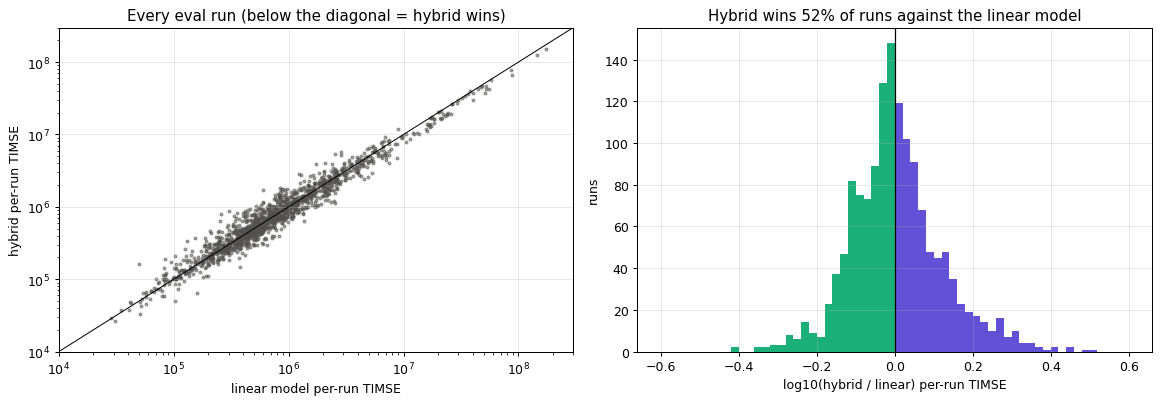

In [3]:
qs = [0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
quant = pd.DataFrame({m: run_scores[m].quantile(qs) for m in MODELS[:3]})
quant["hybrid / linear"] = quant["hybrid"] / quant["linear_model"]
quant["hybrid / baseline"] = quant["hybrid"] / quant["final_baseline"]
quant.index = [f"p{int(q * 100)}" for q in qs]
display(fmt(quant))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
lo, hi = 1e4, 3e8
ax.plot([lo, hi], [lo, hi], color="k", lw=0.8)
ax.scatter(run_scores["linear_model"], run_scores["hybrid"], s=5, alpha=0.5, color="#52514e")
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi),
       xlabel="linear model per-run TIMSE", ylabel="hybrid per-run TIMSE",
       title="Every eval run (below the diagonal = hybrid wins)")
ax = axes[1]
r = np.log10(vs_lin.dropna())
bins = np.linspace(-0.6, 0.6, 61)
ax.hist(r[r < 0], bins=bins, color=WIN)
ax.hist(r[r >= 0], bins=bins, color=LOSE)
ax.axvline(0, color="k", lw=1)
ax.set(xlabel="log10(hybrid / linear) per-run TIMSE", ylabel="runs",
       title=f"Hybrid wins {(r < 0).mean():.0%} of runs against the linear model")
fig.tight_layout()

**Forecasts along the year.** The observed speed against the hybrid's and the linear model's
forecasts: the first eval run, then one run every 3 days. Runs are 72 h long, so the forecasts tile
the year without overlapping. Dotted lines mark each run's `t0`. Where the two forecasts differ, the
trees made a correction.

121 non-overlapping runs; per-run mean TIMSE: {'hybrid': '1.79e+06', 'linear_model': '1.88e+06', 'final_baseline': '2.17e+06', 'persistence': '4.4e+06'}


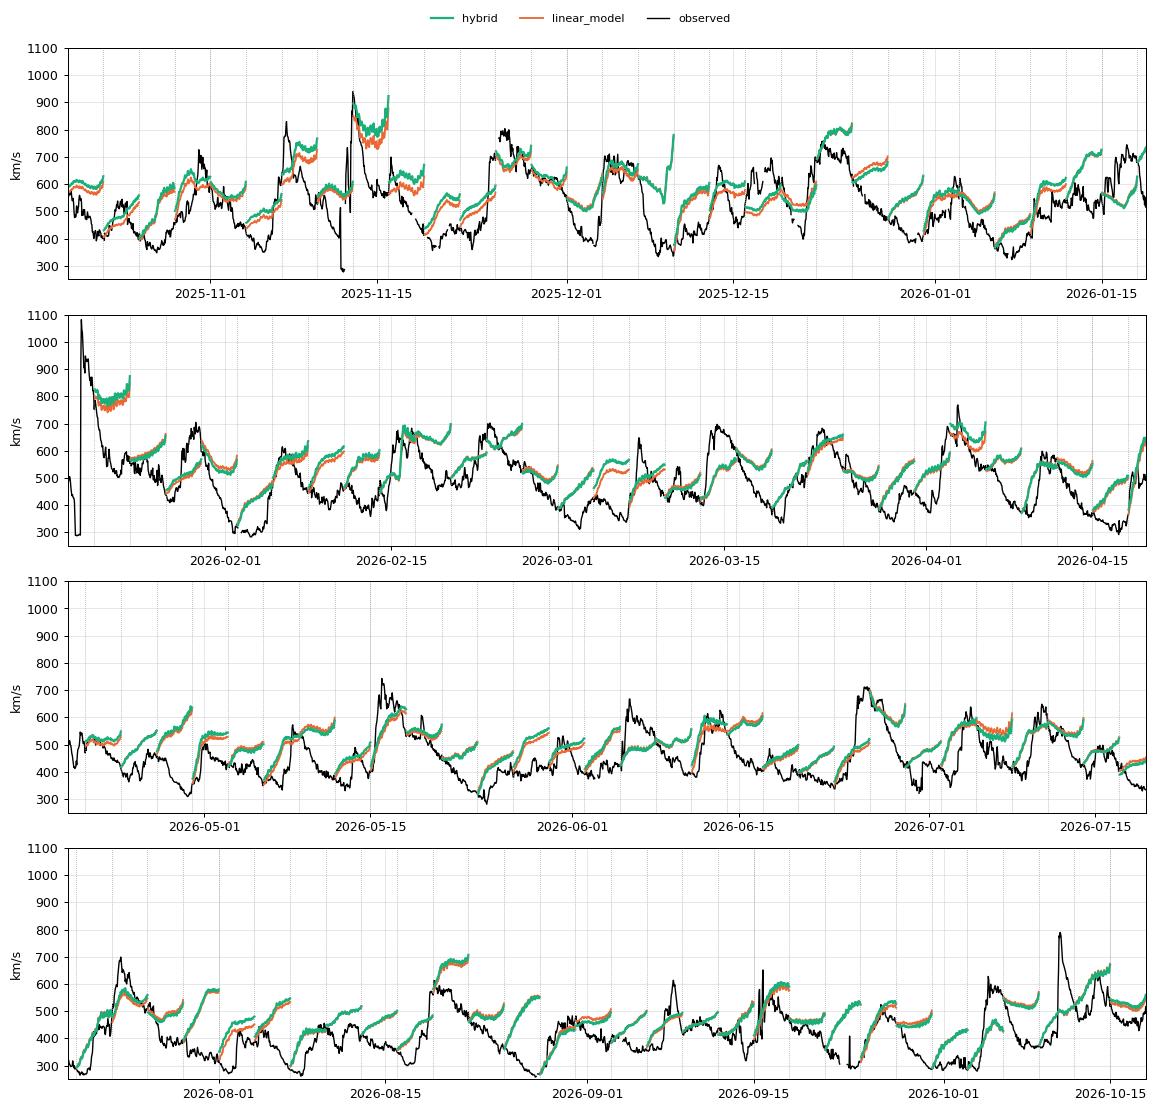

In [4]:
STRIDE = 72 // 6  # runs are 6-hourly; every 12th run is 3 days apart
tiled = np.arange(0, len(t0s), STRIDE)
tiled_times = [t0s[i] + pd.to_timedelta(lead, unit="h") for i in tiled]
valid_hours = tiled_times[0].append(tiled_times[1:])
# consecutive runs: no overlap and no gap
assert valid_hours.is_unique and (np.diff(valid_hours.asi8) == 3600 * 10**9).all()

tiled_scores = run_scores.iloc[tiled]
print(f"{len(tiled)} non-overlapping runs; per-run mean TIMSE:",
      {m: f"{tiled_scores[m].mean():.3g}" for m in MODELS})

quarters = pd.date_range(t0s[0], t0s[tiled[-1]] + pd.Timedelta(hours=HORIZON + 1), periods=5)
fig, axes = plt.subplots(4, 1, figsize=(13, 12))
for k, ax in enumerate(axes):
    lo, hi = quarters[k], quarters[k + 1]
    obs = series[lo:hi]
    ax.plot(obs.index, obs, color="k", lw=1.1)
    for r, i in enumerate(tiled):  # one line per run, so separate runs aren't joined
        if lo <= t0s[i] < hi:
            for m in ("linear_model", "hybrid"):
                ax.plot(tiled_times[r], forecasts[m][i], **STYLE[m])
    for t in t0s[tiled][(t0s[tiled] >= lo) & (t0s[tiled] < hi)]:
        ax.axvline(t, color="0.6", lw=0.6, ls=":")
    ax.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.1), "observed")],
             models=["hybrid", "linear_model"])

## 2. By regime

Runs are labelled by what happened during their 72 target hours (`ev.classify_runs`), as in the
other analyses. For each regime:
- **runs** and their per-run mean TIMSE for each model;
- **share of the change vs linear:** the regime's share of the overall change in the sum of per-run TIMSE, hybrid minus linear (negative is a gain for the hybrid);
- **median ratios and win rates:** hybrid / linear and hybrid / baseline;
- **pooled TIMSE** of the hybrid relative to the linear model.

In [5]:
cond_start = pd.Timestamp("2025-07-01T00:00Z")
minutes = ev.load_conditions(cond_start, EVAL_END)
hourly = minutes.resample("h").mean().reindex(
    pd.date_range(cond_start, EVAL_END, freq="h", inclusive="left", name="Time")
)
events = ev.detect_icmes(hourly, ev.detect_shocks(minutes))
cme = ev.cme_mask(hourly.index, events)
possible = ev.cme_mask(hourly.index, events, ("possible ICME",))
arrivals = ev.detect_stream_arrivals(hourly["speed"], cme | possible)
cme_hours = cme.reindex(series.index, fill_value=False)
possible_hours = possible.reindex(series.index, fill_value=False)
regime = pd.Series(ev.classify_runs(t0s, actual, cme_hours, arrivals, possible_hours),
                   index=t0s, name="regime")
no_cme = regime.isin(ev.NO_CME).to_numpy()

diff = run_scores["hybrid"] - run_scores["linear_model"]
total_change = diff.sum()


def regime_row(sel):
    return {
        "runs": int(sel.sum()),
        "hybrid mean": run_scores.loc[sel, "hybrid"].mean(),
        "linear mean": run_scores.loc[sel, "linear_model"].mean(),
        "baseline mean": run_scores.loc[sel, "final_baseline"].mean(),
        "share of change vs linear": diff[sel].sum() / abs(total_change),
        "median hybrid / linear": vs_lin[sel].median(),
        "hybrid beats linear": (vs_lin[sel] < 1).mean(),
        "median hybrid / baseline": vs_base[sel].median(),
        "hybrid beats baseline": (vs_base[sel] < 1).mean(),
        "pooled hybrid / linear": timse(actual[sel], forecasts["hybrid"][sel])
        / timse(actual[sel], forecasts["linear_model"][sel]),
    }


rows = {r: regime_row((regime == r).to_numpy()) for r in ev.REGIMES}
rows["all no-CME"] = regime_row(no_cme)
rows["all"] = regime_row(np.ones(len(t0s), dtype=bool))
by_regime = pd.DataFrame(rows).T
by_regime["runs"] = by_regime["runs"].astype(int)
fmt(by_regime)

[solar_wind_events] plasma: 476/476 days


[solar_wind_events] mag: 476/476 days


,runs,hybrid mean,linear mean,baseline mean,share of change vs linear,median hybrid / linear,hybrid beats linear,median hybrid / baseline,hybrid beats baseline,pooled hybrid / linear
CME,295,6.22e+06,6.87e+06,7.78e+06,-0.854,0.992,0.532,0.86,0.692,0.92
possible CME,81,5.91e+05,5.64e+05,6.88e+05,0.00974,0.92,0.654,0.717,0.778,1.09
stream arrival,304,2.42e+06,2.6e+06,2.17e+06,-0.246,0.969,0.592,1.01,0.487,0.881
fast stream,105,1.25e+06,1.28e+06,1.45e+06,-0.0127,0.98,0.571,0.898,0.562,0.993
slow wind,186,6.54e+05,6.43e+05,9.06e+05,0.00886,0.973,0.57,0.649,0.769,1.07
intermediate,477,7.09e+05,6.65e+05,8.81e+05,0.0939,1.04,0.426,0.822,0.637,1.08
all no-CME,1072,1.24e+06,1.27e+06,1.31e+06,-0.156,0.996,0.512,0.876,0.61,0.911
all,1448,2.22e+06,2.37e+06,2.59e+06,-1,0.992,0.524,0.863,0.636,0.921


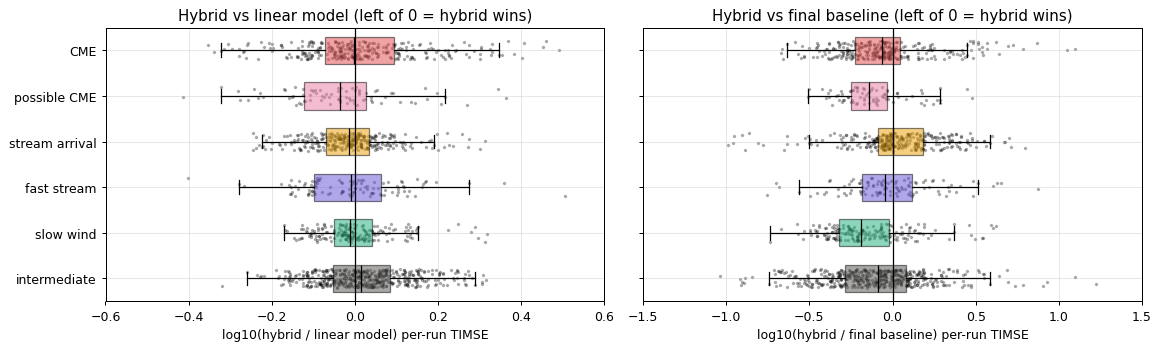

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = ev.REGIMES
for ax, (r, label, lim) in zip(
        axes, [(vs_lin, "linear model", 0.6), (vs_base, "final baseline", 1.5)], strict=True):
    data = [np.log10(r[(regime == g).to_numpy()].dropna()) for g in order]
    parts = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True,
                       widths=0.6, medianprops={"color": "k"})
    ax.set_yticks(range(1, len(order) + 1), order)
    for patch, g in zip(parts["boxes"], order, strict=True):
        patch.set(facecolor=REGIME_COLORS[g], alpha=0.5)
    rng = np.random.default_rng(0)
    for k, d in enumerate(data, 1):
        ax.scatter(d, k + rng.uniform(-0.2, 0.2, len(d)), s=3, color="k", alpha=0.25)
    ax.axvline(0, color="k", lw=1)
    ax.set(xlabel=f"log10(hybrid / {label}) per-run TIMSE", xlim=(-lim, lim),
           title=f"Hybrid vs {label} (left of 0 = hybrid wins)")
axes[0].invert_yaxis()
fig.tight_layout()

## 3. Bias and level

Mean residual and RMSE by lead for each regime (top: mean residual, negative = over-forecast;
bottom: RMSE). Then the forecast distribution at 24 h and 72 h against the observed speeds: both
earlier models rarely forecast slow wind at 72 h.

bias 6 h RMSE 6 h bias 24 h RMSE 24 h bias 72 h RMSE 72 h
CME            hybrid            -29.2     76.9     -61.2       123     -88.9       151
               linear_model      -15.9     73.5     -47.9       120     -76.3       142
               final_baseline      -10       74     -42.8       122     -57.7       131
possible CME   hybrid            -16.3     35.1     -54.4        78      -149       159
               linear_model        -14     35.1     -52.2      77.4      -147       156
               final_baseline    -15.1     35.6     -62.7      84.6      -129       143
stream arrival hybrid            -16.1     44.5     -40.3      95.6     -9.03      90.2
               linear_model      -7.68       43     -32.1      93.7    -0.709      86.7
               final_baseline    -9.44     46.1     -49.1       103     -14.3      80.7
fast stream    hybrid            -4.03     52.2     -2.49      80.6      -160       178
               linear_model       5.35     50.6      6.68      78.5      -151       171
               final_baseline     7.82     49.3      13.4      77.6      -133       158
slow wind      hybrid            -18.9       27     -77.2      86.2      -152       162
               linear_model      -18.7     26.9     -76.6      86.2      -152       161
               final_baseline    -24.6     31.7     -97.8       108      -166       175
intermediate   hybrid            -15.6     35.4     -63.2        82      -157       171
               linear_model      -13.6       33     -61.2      79.7      -154       169
               final_baseline    -17.5     35.1     -74.8      90.1      -159       174

p1  p10 median  p90
24 h hybrid          367  425    511  639
     linear_model    370  424    505  626
     final_baseline  388  440    524  617
     observed        281  349    448  623
72 h hybrid          438  487    569  686
     linear_model    435  488    563  672
     final_baseline  447  502    567  655
     observed        281  349    448  623

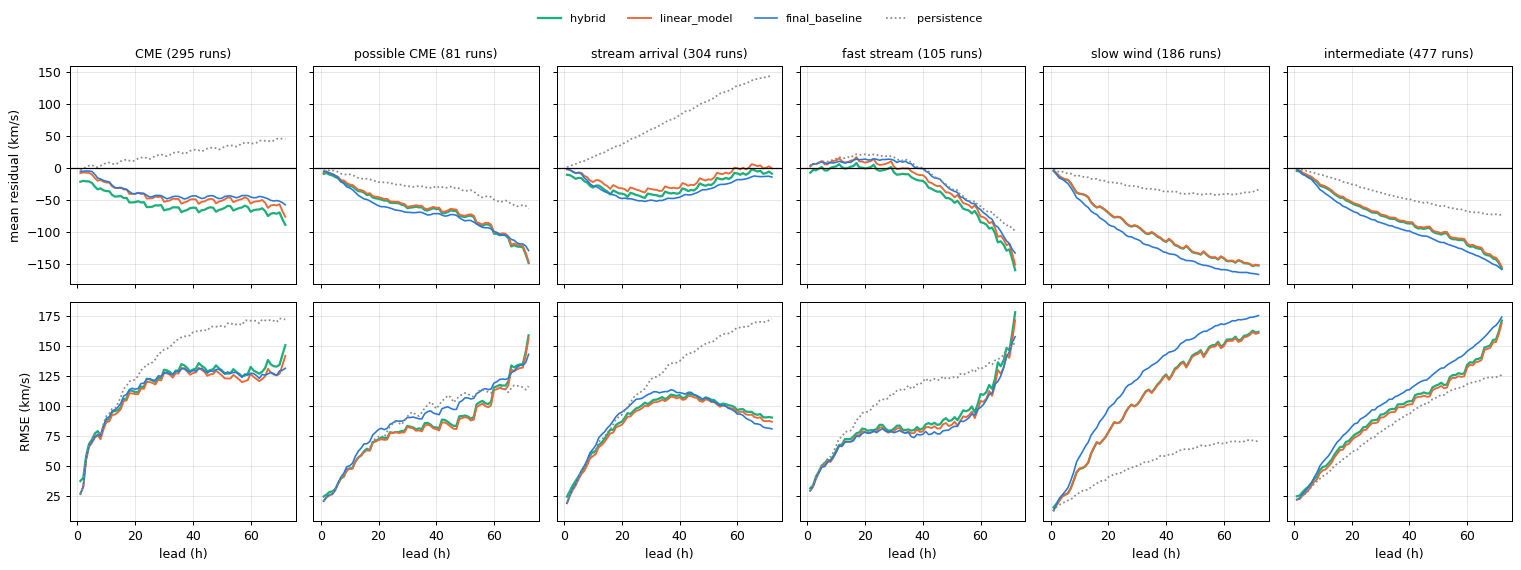

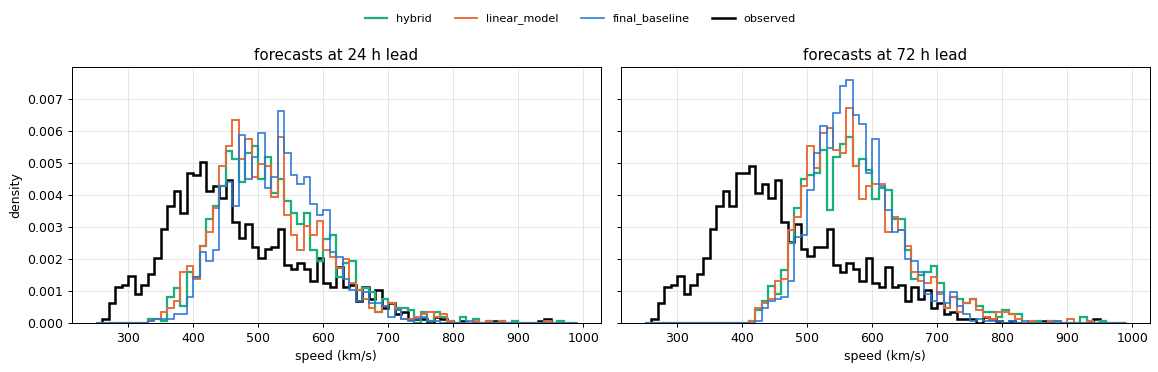

In [7]:
fig, axes = plt.subplots(2, len(ev.REGIMES), figsize=(17, 6), sharex=True, sharey="row")
bias_rows = {}
for col, g in enumerate(ev.REGIMES):
    sel = (regime == g).to_numpy()
    for m in MODELS:
        r = residuals[m][sel]
        axes[0, col].plot(lead, np.nanmean(r, axis=0), **STYLE[m])
        axes[1, col].plot(lead, np.sqrt(np.nanmean(r**2, axis=0)), **STYLE[m])
        if m != "persistence":
            for k in (6, 24, 72):
                bias_rows[(g, m)] = bias_rows.get((g, m), {}) | {
                    f"bias {k} h": np.nanmean(r[:, k - 1]),
                    f"RMSE {k} h": np.sqrt(np.nanmean(r[:, k - 1] ** 2)),
                }
    axes[0, col].axhline(0, color="k", lw=1)
    axes[0, col].set_title(f"{g} ({sel.sum()} runs)", fontsize=10)
    axes[1, col].set_xlabel("lead (h)")
axes[0, 0].set_ylabel("mean residual (km/s)")
axes[1, 0].set_ylabel("RMSE (km/s)")
fig.tight_layout()
model_legend(fig)
display(fmt(pd.DataFrame(bias_rows).T))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
bins = np.arange(250, 1000, 10)
quant = {}
for ax, k in zip(axes, (24, 72), strict=True):
    obs = actual[:, k - 1][np.isfinite(actual[:, k - 1])]
    ax.hist(obs, bins=bins, histtype="step", color="k", lw=2, density=True)
    for m in MODELS[:3]:
        ax.hist(forecasts[m][:, k - 1], bins=bins, histtype="step", density=True, **STYLE[m])
        quant[(f"{k} h", m)] = np.quantile(forecasts[m][:, k - 1], [0.01, 0.1, 0.5, 0.9])
    quant[(f"{k} h", "observed")] = np.quantile(obs, [0.01, 0.1, 0.5, 0.9])
    ax.set(title=f"forecasts at {k} h lead", xlabel="speed (km/s)")
axes[0].set_ylabel("density")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")], models=MODELS[:3])
fmt(pd.DataFrame(quant, index=["p1", "p10", "median", "p90"]).T)

## 4. Stream arrivals

A superposed-epoch view of the non-CME stream arrivals: forecasts valid at each hour around the
arrival (hour 0), made about 1, 2 or 3 days earlier, as the median over arrivals. Black is the median
observed speed. The table gives the share of the observed rise each model reproduces: the mean over
+12…+36 h minus the mean over −36…−12 h, forecast over observed, median over arrivals.

29 non-CME stream arrivals


,hybrid: share of rise,linear_model: share of rise,final_baseline: share of rise,persistence: share of rise
~1 day ahead (19-30 h),0.384,0.387,0.27,0.42
~2 days ahead (43-54 h),0.146,0.127,0.0355,-0.156
~3 days ahead (61-72 h),-0.0355,0.0167,0.0236,-0.251


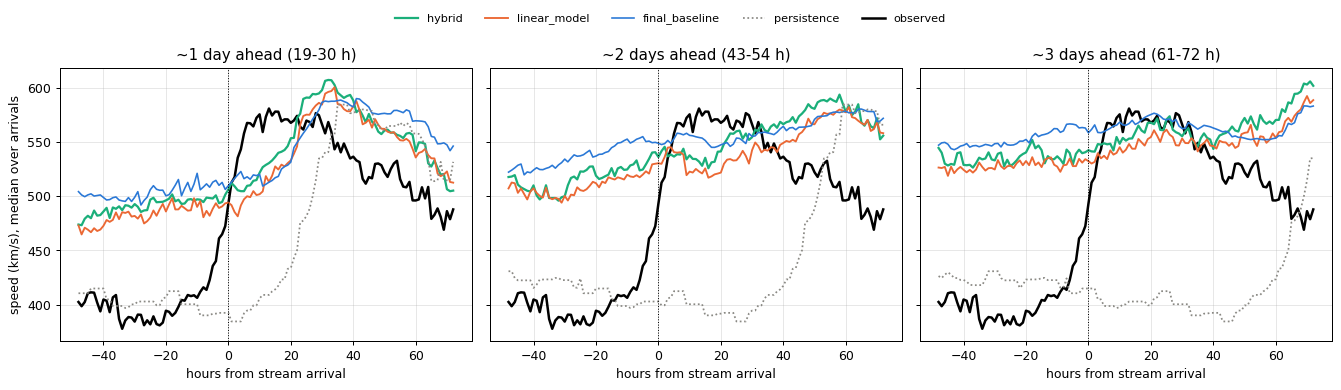

In [8]:
eval_arrivals = arrivals[(arrivals >= TRAIN_END + pd.Timedelta(days=3)) & (arrivals < EVAL_END)]
valid = t0s.values[:, None] + lead[None, :] * np.timedelta64(1, "h")
lead_grid = np.broadcast_to(lead, valid.shape)
groups = {"~1 day ahead (19-30 h)": (19, 30), "~2 days ahead (43-54 h)": (43, 54),
          "~3 days ahead (61-72 h)": (61, 72)}
rel_hours = np.arange(-48, 73)
epoch, capture = {}, {}
for gname, (lo, hi) in groups.items():
    stacks = {m: [] for m in MODELS}
    caps = {m: [] for m in MODELS}
    obs_stack = []
    for a in eval_arrivals:
        rel = (valid - a.tz_convert(None).to_datetime64()) / np.timedelta64(1, "h")
        sel = (rel >= -48) & (rel <= 72) & (lead_grid >= lo) & (lead_grid <= hi)
        obs = series.reindex(a + pd.to_timedelta(rel_hours, unit="h")).to_numpy()
        obs_stack.append(obs)
        rise_obs = np.nanmean(obs[(rel_hours >= 12) & (rel_hours <= 36)]) - np.nanmean(
            obs[(rel_hours >= -36) & (rel_hours <= -12)])
        for m in MODELS:
            df = pd.DataFrame({"rel": rel[sel].round().astype(int), "f": forecasts[m][sel]})
            curve = df.groupby("rel")["f"].mean().reindex(rel_hours)
            stacks[m].append(curve.to_numpy())
            after = curve[(curve.index >= 12) & (curve.index <= 36)].mean()
            before = curve[(curve.index >= -36) & (curve.index <= -12)].mean()
            caps[m].append((after - before) / rise_obs)
    epoch[gname] = ({m: np.nanmedian(np.array(stacks[m]), axis=0) for m in MODELS},
                    np.nanmedian(np.array(obs_stack), axis=0))
    capture[gname] = {m: np.nanmedian(caps[m]) for m in MODELS}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (gname, (curves, obs)) in zip(axes, epoch.items(), strict=True):
    ax.plot(rel_hours, obs, color="k", lw=2)
    for m in MODELS:
        ax.plot(rel_hours, curves[m], **STYLE[m])
    ax.axvline(0, color="k", lw=0.8, ls=":")
    ax.set(title=gname, xlabel="hours from stream arrival")
axes[0].set_ylabel("speed (km/s), median over arrivals")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")])
print(f"{len(eval_arrivals)} non-CME stream arrivals")
fmt(pd.DataFrame(capture).T.rename(columns=lambda m: f"{m}: share of rise"))

## 5. What the trees do

### 5.1 The size of the corrections

The trees' correction to the linear forecast (hybrid − linear, km/s), by lead: the median and the
10–90% range over all runs, and the mean by regime.

,mean 6 h,mean 24 h,mean 72 h,mean |correction|
CME,13.2,13.3,12.9,15.9
possible CME,2.58,2.51,2.31,12.5
stream arrival,8.2,8.24,8.4,12
fast stream,9.43,9.01,8.25,12
slow wind,0.192,0.501,0.665,7.16
intermediate,1.97,1.99,2.34,9.47


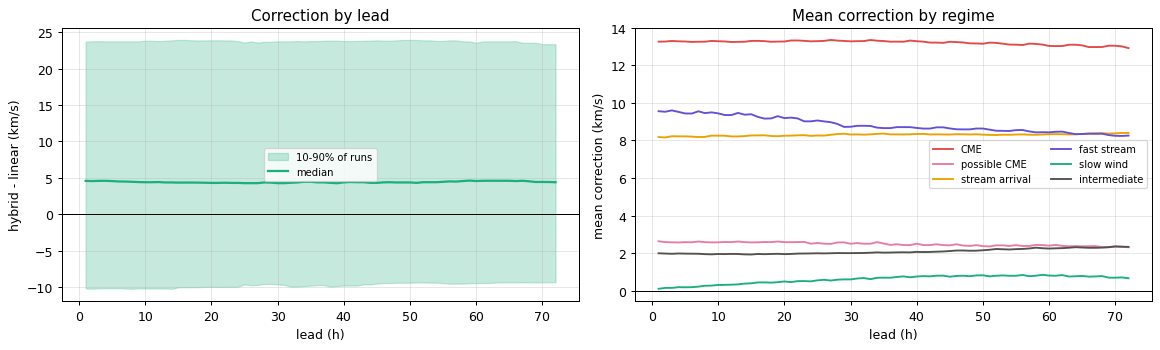

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
q10, q50, q90 = np.nanquantile(correction, [0.1, 0.5, 0.9], axis=0)
axes[0].fill_between(lead, q10, q90, color=STYLE["hybrid"]["color"], alpha=0.25,
                     label="10-90% of runs")
axes[0].plot(lead, q50, color=STYLE["hybrid"]["color"], lw=1.8, label="median")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(xlabel="lead (h)", ylabel="hybrid - linear (km/s)", title="Correction by lead")
axes[0].legend(fontsize=8)
for g in ev.REGIMES:
    sel = (regime == g).to_numpy()
    axes[1].plot(lead, correction[sel].mean(axis=0), color=REGIME_COLORS[g], lw=1.5, label=g)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="lead (h)", ylabel="mean correction (km/s)", title="Mean correction by regime")
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
summary = pd.DataFrame({
    g: {f"mean {k} h": correction[(regime == g).to_numpy(), k - 1].mean() for k in (6, 24, 72)}
    | {"mean |correction|": np.abs(correction[(regime == g).to_numpy()]).mean()}
    for g in ev.REGIMES
}).T
fmt(summary)

### 5.2 The trees

The table counts how often each input is used in a split of the 100 depth-2 trees. The gain
share comes from the selection on the training folds (`xgboost_hybrid_config.json`, before taming).
The root split of each tree (its most important cut) is counted by input. The last lines check the
untamed rule's condition (5-day M-flare count ≥ 48): how rare it is, and where the tamed trees now
split on the flare count.

In [10]:
trees = hybrid.trees
cols = list(hybrid.config.columns)
inner = trees.left >= 0
used = pd.Series([cols[f] for f in trees.feature[inner]]).value_counts()
gain = pd.Series(json.loads(config_path("linear").read_text())["selection"]["gain_share"])
usage = pd.DataFrame({"splits": used, "gain share (folds)": gain}).fillna(0)
usage = usage[usage["splits"] > 0].sort_values("splits", ascending=False)
display(fmt(usage))
roots = pd.DataFrame({"tree": range(trees.n_trees),
                      "root split": [cols[trees.feature[r]] for r in trees.roots],
                      "threshold": [float(trees.threshold[r]) for r in trees.roots]})
display(roots["root split"].value_counts().rename("trees with this root split").to_frame().T)

from training.datasets import load_train  # noqa: E402
from training.xgboost_model import CACHE_DIR, hourly_runs  # noqa: E402

train_t0s = hourly_runs(load_train())
train_tab = feature_table(train_t0s, tuple(INPUTS), CACHE_DIR / "table_train.pkl")
flares = "m_flares_count_120h"
cut = 48.0  # the untamed hybrid's rule
splits = sorted({float(t) for f, t in zip(trees.feature[inner], trees.threshold[inner], strict=True)
                 if cols[f] == flares})
print(f"tamed trees split on {flares} at: {splits}")
high_train = train_tab[flares] >= cut
high_eval = table[flares] >= cut
print(f"{flares} >= {cut:g}: {high_train.mean():.2%} of training hours "
      f"({high_train.sum()} h; days: {sorted(set(train_t0s[high_train].strftime('%Y-%m')))}), "
      f"{high_eval.mean():.2%} of eval runs (days: "
      f"{sorted(set(t0s[high_eval.to_numpy()].strftime('%Y-%m-%d')))})")
print(f"mean correction on those eval runs: {correction[high_eval.to_numpy()].mean():.0f} km/s; "
      f"on the others: {correction[~high_eval.to_numpy()].mean():.1f} km/s")

,splits,gain share (folds)
log_p310_mean_1h,35,0.0474
f107_mean_168h,31,0.0918
ch_disk_at_0h,22,0.0547
polarity_lag27_72h,17,0.0372
ch_cm_at_48h,14,0.0412
xray_peak_max_120h,13,0.0462
bt_mean_6h,12,0.0208
rec_27d,12,0.0567
bt_max_6h,9,0.0121
polarity_mean_48h,9,0.0317


root split,f107_mean_168h,log_p310_mean_1h,ch_disk_at_0h,bt_mean_6h,polarity_lag27_72h,ch_cm_at_12h,bt_max_6h,density_lag13_72h,xray_peak_max_120h,rec_27d,last,polarity_mean_48h,ch_cm_at_48h,ch_cm_at_24h,bz_min_24h
trees with this root split,18,11,10,9,9,7,6,5,5,5,4,4,3,2,2


tamed trees split on m_flares_count_120h at: [13.0, 15.0, 18.0, 19.0]
m_flares_count_120h >= 48: 0.66% of training hours (233 h; days: ['2024-05', '2024-08']), 0.90% of eval runs (days: ['2026-02-04', '2026-02-05', '2026-02-06', '2026-02-07'])
mean correction on those eval runs: 14 km/s; on the others: 5.9 km/s


### 5.3 Ablation: which tree inputs matter on the eval year

The linear anchor is kept fixed, and one tree input at a time is marked missing for every run,
exactly as a live run with that feed down would see it:
- **most inputs:** the trees take their learned default branch;
- **the three never missing in training** (M-flare count, 120 h peak flare flux, 7-day F10.7): the input takes its training median, because their default branch was never trained (`impute_values`, section 5.2).

The change is in per-run mean and median TIMSE and pooled TIMSE relative to the full hybrid;
positive means the input helps. "All regressors missing" leaves the trees only the lead, the speed
terms and the anchor. This analyses the fitted model; it is not a refit.

In [11]:
def without(names):
    xa = x.copy()
    for c in names:
        xa[:, INPUTS.index(c)] = np.nan
    rows, _ = hybrid.rows(values, pos, xa, anchor=anchor)  # imputes as live
    return np.clip(anchor + trees.predict(rows).reshape(len(pos), HORIZON), 200, 1500)


def scores(f):
    s = run_timse(f, actual)
    return np.nanmean(s), np.nanmedian(s), timse(actual, f)


print("imputed with the training median when missing:", hybrid.impute_values)
full = scores(forecasts["hybrid"])
groups_ab = {c: [c] for c in TREE_FEATURES}
groups_ab["all regressors missing"] = TREE_FEATURES
rows_ab = {}
for name, members in groups_ab.items():
    s = scores(without(members))
    rows_ab[name] = {"per-run mean, worse by": s[0] / full[0] - 1,
                     "per-run median, worse by": s[1] / full[1] - 1,
                     "pooled TIMSE, worse by": s[2] / full[2] - 1}
ablation = pd.DataFrame(rows_ab).T.sort_values("pooled TIMSE, worse by", ascending=False)
fmt(ablation)

imputed with the training median when missing: {'xray_peak_max_120h': -4.573897361755371, 'f107_mean_168h': 153.92857360839844, 'm_flares_count_120h': 3.0}


,"per-run mean, worse by","per-run median, worse by","pooled TIMSE, worse by"
log_p310_mean_1h,0.0201,-0.0145,0.0422
all regressors missing,0.0422,0.0529,0.0313
bt_mean_6h,0.0176,-0.0314,0.0301
density_lag13_72h,0.00653,-0.046,0.0169
bt_max_6h,0.0117,-0.00794,0.0156
log_temperature_mean_48h,0.00647,-0.0327,0.0076
xray_peak_max_120h,0.000735,-0.0129,0.00349
speed_mean_48h,0.000482,0,0.00311
density_mean_24h,0.000932,-0.00664,0.00241
f107_mean_168h,0.00703,-0.00604,0.000786


### 5.4 The coronal-hole effect

The linear model over-forecast when the central-meridian coronal hole was large: it won only 45%
of runs in the largest quarter. The trees see the strip at several lags and can level the effect
off. The table compares the three models by quarter of `ch_cm_at_12h`, and on the runs without a
coronal-hole image (the linear model's submodel runs). The figure shows the mean correction at
48–72 h by strip area.

,runs,median hybrid / linear,hybrid beats linear,median hybrid / baseline,median linear / baseline,"residual 72 h, hybrid","residual 72 h, linear",mean correction 48-72 h
no image (submodel),279,1.01,0.498,0.897,0.879,-112,-94.1,18.5
Q1 (small),293,0.968,0.584,0.576,0.613,-118,-118,0.0327
Q2,292,0.943,0.62,0.691,0.743,-102,-100,1.82
Q3,292,1.04,0.459,0.955,0.933,-104,-98.4,5.75
Q4 (large),292,1.01,0.459,1.09,1.1,-118,-114,4.51


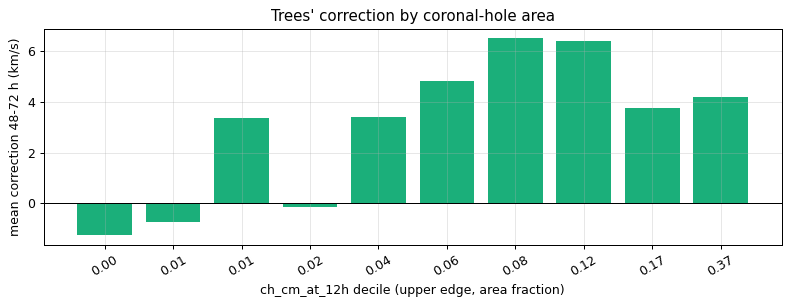

In [12]:
ch = table["ch_cm_at_12h"]
no_image = linear.uses_fallback(x_lin)
groups_ch = pd.Series(np.where(no_image, "no image (submodel)", ""), index=t0s, dtype=object)
groups_ch[~no_image] = pd.qcut(ch[~no_image], 4, labels=["Q1 (small)", "Q2", "Q3",
                                                        "Q4 (large)"]).astype(str)
rows_ch = {}
for g in ["no image (submodel)", "Q1 (small)", "Q2", "Q3", "Q4 (large)"]:
    sel = (groups_ch == g).to_numpy()
    rows_ch[g] = {"runs": int(sel.sum()),
                  "median hybrid / linear": vs_lin[sel].median(),
                  "hybrid beats linear": (vs_lin[sel] < 1).mean(),
                  "median hybrid / baseline": vs_base[sel].median(),
                  "median linear / baseline": lin_vs_base[sel].median(),
                  "residual 72 h, hybrid": np.nanmean(residuals["hybrid"][sel, 71]),
                  "residual 72 h, linear": np.nanmean(residuals["linear_model"][sel, 71]),
                  "mean correction 48-72 h": correction[sel, 47:].mean()}
display(fmt(pd.DataFrame(rows_ch).T))

fig, ax = plt.subplots(figsize=(9, 3.5))
obs = ~no_image
bins_ch = pd.qcut(ch[obs], 10, duplicates="drop")
mc = pd.Series(correction[obs, 47:].mean(axis=1), index=t0s[obs]).groupby(bins_ch,
                                                                         observed=True).mean()
ax.bar(range(len(mc)), mc.to_numpy(), color=STYLE["hybrid"]["color"])
ax.set_xticks(range(len(mc)), [f"{iv.right:.2f}" for iv in mc.index], rotation=30)
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="ch_cm_at_12h decile (upper edge, area fraction)",
       ylabel="mean correction 48-72 h (km/s)", title="Trees' correction by coronal-hole area")
fig.tight_layout()

### 5.5 Taming the flare-count rule

The training folds can't test the untamed rule out of sample:
- **Fold 1:** its training data never exceeds 33 flares, so its model can't learn the rule.
- **Fold 2:** its model learns the rule from 2024, but its validation year peaks at 46 flares, below the threshold.

So each variant was judged on two things, both from training data only:
- its **fold score**;
- its **leaf support**: the number of distinct training days whose runs reach each leaf.

A leaf reached on fewer than 30 days (about a solar rotation) rests on a single episode. The rule,
fixed before any variant was scored, was to keep the best fold score among the variants with no
such leaf (`python -m training.xgboost_model tame`).

The table lists every variant:
- **min_leaf_days:** the support of its weakest leaf;
- **max_thin_correction:** the largest correction any training run gets from leaves under 30 days.

The figure shows the leaf support of the shipped (tamed) trees.

,n_features,min_child_weight,n_trees,objective,fold1,fold2,min_leaf_days,thin_leaves,max_thin_correction,splits_on_flares
variant,,,,,,,,,,
shipped,25,100,25,0.453,0.534,0.385,3,36,150,"m_flares_count_120h, xray_peak_max_120h"
min_child_weight 1000,25,1000,50,0.449,0.536,0.377,3,58,196,"m_flares_count_120h, xray_peak_max_120h"
min_child_weight 3000,25,3000,50,0.45,0.531,0.382,9,38,110,"m_flares_count_120h, xray_peak_max_120h"
min_child_weight 5000,25,5000,50,0.452,0.538,0.38,19,25,62.3,"m_flares_count_120h, xray_peak_max_120h"
min_child_weight 10000,25,10000,50,0.455,0.541,0.383,44,0,0,"m_flares_count_120h, xray_peak_max_120h"
min_child_weight 20000,25,20000,100,0.453,0.539,0.38,72,0,0,"m_flares_count_120h, xray_peak_max_120h"
min_child_weight 40000,25,40000,100,0.456,0.546,0.38,193,0,0,"m_flares_count_120h, xray_peak_max_120h"
"min_child_weight 10000, depth 3",25,10000,25,0.454,0.538,0.383,49,0,0,xray_peak_max_120h
"no flare count, mcw 100",24,100,50,0.455,0.537,0.385,2,44,72.2,xray_peak_max_120h


shipped trees: 341 leaves; the weakest is reached on 72 training days; median 398


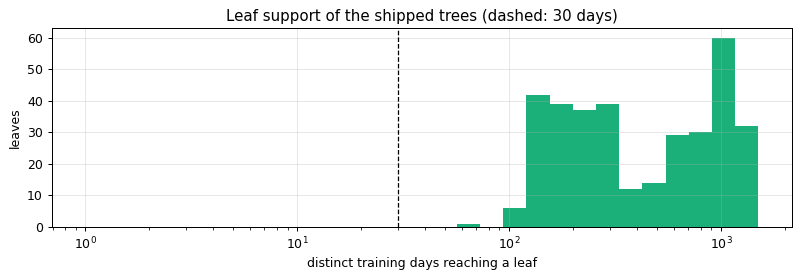

In [13]:
from training.xgboost_model import leaf_support  # noqa: E402

taming = pd.read_csv("xgboost_hybrid_taming.csv").set_index("variant")
display(fmt(taming[["n_features", "min_child_weight", "n_trees", "objective", "fold1", "fold2",
                    "min_leaf_days", "thin_leaves", "max_thin_correction", "splits_on_flares"]]))
tx_inputs = train_tab[INPUTS].to_numpy(dtype=np.float32)
train_series = load_train()
support = leaf_support(hybrid, train_series.to_numpy(dtype=float),
                       train_series.index.get_indexer(train_t0s), tx_inputs, train_t0s)
print(f"shipped trees: {len(support)} leaves; the weakest is reached on {support['days'].min()} "
      f"training days; median {support['days'].median():.0f}")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(support["days"], bins=np.logspace(0, np.log10(1500), 30), color=STYLE["hybrid"]["color"])
ax.axvline(30, color="k", lw=1, ls="--")
ax.set(xscale="log", xlabel="distinct training days reaching a leaf", ylabel="leaves",
       title="Leaf support of the shipped trees (dashed: 30 days)")
fig.tight_layout()

## 6. Through the year and the biggest differences

### 6.1 Month by month

Per-run mean TIMSE by month, the hybrid's win share against the linear model, and each month's
share of the year's change in the per-run total, hybrid minus linear (negative = a gain for the
hybrid; the column sums to −1).

,runs,hybrid mean,linear mean,baseline mean,hybrid beats linear,CME runs,share of change vs linear
2025-10,48,1.35e+06,1.28e+06,1.71e+06,0.458,0,0.0147
2025-11,120,6.9e+06,8.06e+06,8.16e+06,0.483,0.4,-0.618
2025-12,124,1.72e+06,1.72e+06,1.53e+06,0.484,0.242,0.00431
2026-01,124,7.12e+06,7.42e+06,8.6e+06,0.516,0.25,-0.166
2026-02,112,1.14e+06,1.11e+06,1.47e+06,0.509,0.277,0.0139
2026-03,124,1.31e+06,1.37e+06,1.33e+06,0.508,0.355,-0.0296
2026-04,120,1.26e+06,1.27e+06,1.35e+06,0.383,0.125,-0.00689
2026-05,124,8.86e+05,9.1e+05,1.29e+06,0.581,0.129,-0.0131
2026-06,120,1.21e+06,1.31e+06,1.54e+06,0.6,0.383,-0.0545
2026-07,124,6.97e+05,7.89e+05,9.89e+05,0.726,0.0645,-0.0508


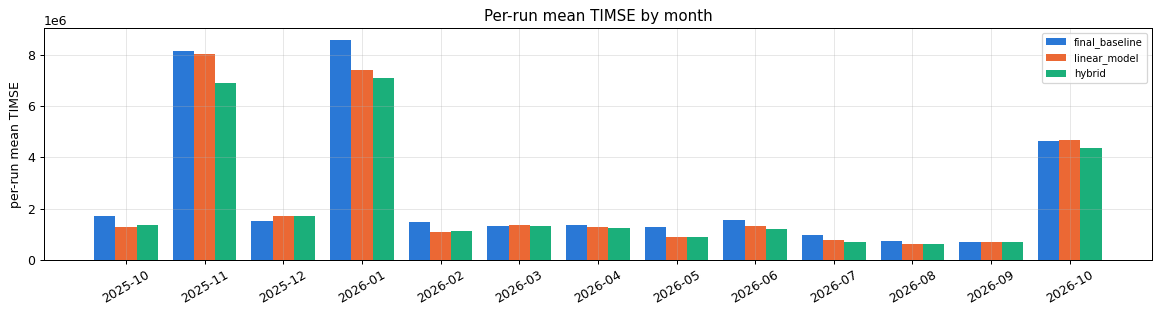

In [14]:
month = pd.Series(t0s.strftime("%Y-%m"), index=t0s)
monthly = pd.DataFrame({
    "runs": month.value_counts().sort_index(),
    "hybrid mean": run_scores["hybrid"].groupby(month).mean(),
    "linear mean": run_scores["linear_model"].groupby(month).mean(),
    "baseline mean": run_scores["final_baseline"].groupby(month).mean(),
    "hybrid beats linear": (vs_lin < 1).groupby(month).mean(),
    "CME runs": (regime == "CME").groupby(month).mean(),
    "share of change vs linear": diff.groupby(month).sum() / abs(total_change),
})
fig, ax = plt.subplots(figsize=(13, 3.6))
xm = np.arange(len(monthly))
for off, m, c in ((-0.27, "baseline mean", "final_baseline"), (0, "linear mean", "linear_model"),
                  (0.27, "hybrid mean", "hybrid")):
    ax.bar(xm + off, monthly[m], 0.27, color=STYLE[c]["color"], label=c)
ax.set_xticks(xm, monthly.index, rotation=30)
ax.set(ylabel="per-run mean TIMSE", title="Per-run mean TIMSE by month")
ax.legend(fontsize=8)
fig.tight_layout()
fmt(monthly)

### 6.2 Where the trees help and hurt most

The ten runs where the hybrid gains most over the linear model (largest drop in per-run TIMSE),
and the ten where it loses most. Four examples are plotted: the two largest gains and the two
largest losses. Each panel shows the 48 h before `t0`, then the 72 h forecasts.

Largest gains over the linear model:


,regime,hybrid,linear,baseline,hybrid - linear,hybrid / linear,mean correction,peak observed,ch_cm_at_12h
2026-01-19 18,CME,1.52e+08,1.73e+08,1.89e+08,-2.18e+07,0.874,32.7,1.08e+03,0.194
2025-11-12 06,CME,6.59e+07,8.73e+07,8.77e+07,-2.14e+07,0.755,54.5,940,nan
2026-01-19 12,CME,1.26e+08,1.46e+08,1.56e+08,-1.96e+07,0.866,31.4,1.08e+03,0.193
2025-11-11 12,CME,3.76e+07,5.06e+07,5.26e+07,-1.3e+07,0.743,45.3,940,nan
2025-11-11 18,CME,4.23e+07,5.49e+07,5.58e+07,-1.26e+07,0.77,41.4,940,nan
2025-11-12 00,CME,2.99e+07,4.01e+07,4.66e+07,-1.02e+07,0.745,43.6,940,nan
2025-11-11 06,CME,4.31e+07,5.23e+07,5.05e+07,-9.28e+06,0.823,30.9,940,nan
2026-01-19 06,CME,7.74e+07,8.52e+07,9.3e+07,-7.78e+06,0.909,15.2,1.08e+03,0.179
2025-11-12 18,CME,1.9e+07,2.61e+07,3.01e+07,-7.03e+06,0.73,43.1,940,nan
2025-11-11 00,CME,4.64e+07,5.19e+07,4.88e+07,-5.48e+06,0.894,18.2,940,nan


Largest losses to the linear model:


,regime,hybrid,linear,baseline,hybrid - linear,hybrid / linear,mean correction,peak observed,ch_cm_at_12h
2025-11-07 18,CME,5.41e+06,2.55e+06,1.54e+06,2.86e+06,2.12,54.2,709,nan
2025-11-13 06,CME,5.68e+06,2.85e+06,1.31e+06,2.83e+06,1.99,45.5,845,nan
2026-01-20 00,CME,1.17e+07,9.03e+06,3.16e+06,2.71e+06,1.3,19.7,996,0.194
2025-11-07 12,CME,5.23e+06,2.86e+06,1.6e+06,2.38e+06,1.83,43.4,774,nan
2026-01-20 12,CME,9.23e+06,6.9e+06,2.2e+06,2.33e+06,1.34,23.2,901,0.194
2025-11-08 12,possible CME,3.85e+06,1.74e+06,1.37e+06,2.11e+06,2.21,49.2,665,nan
2025-11-13 12,CME,4.01e+06,2.08e+06,1.8e+06,1.93e+06,1.93,38.7,772,nan
2025-11-08 06,possible CME,2.86e+06,1.24e+06,9.57e+05,1.62e+06,2.31,46.9,665,nan
2025-11-16 06,CME,3.87e+06,2.37e+06,1.77e+06,1.5e+06,1.63,28.5,666,nan
2026-01-17 00,CME,3.97e+07,3.82e+07,4.1e+07,1.49e+06,1.04,-9.01,1.08e+03,0.149


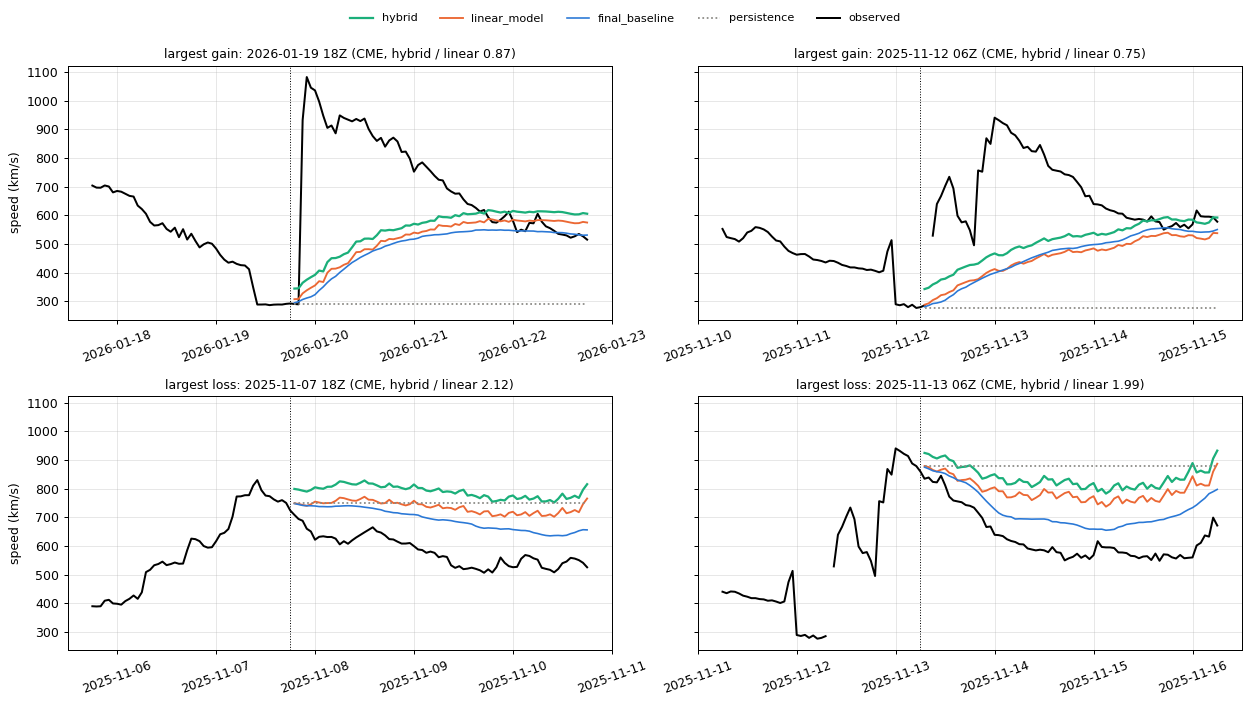

In [15]:
info = pd.DataFrame({
    "regime": regime,
    "hybrid": run_scores["hybrid"],
    "linear": run_scores["linear_model"],
    "baseline": run_scores["final_baseline"],
    "hybrid - linear": diff,
    "hybrid / linear": vs_lin,
    "mean correction": correction.mean(axis=1),
    "peak observed": np.nanmax(actual, axis=1),
    "ch_cm_at_12h": ch,
})
shown = info.copy()
shown.index = shown.index.strftime("%Y-%m-%d %H")
print("Largest gains over the linear model:")
display(fmt(shown.sort_values("hybrid - linear").head(10)))
print("Largest losses to the linear model:")
display(fmt(shown.sort_values("hybrid - linear", ascending=False).head(10)))

picks = ([("gain", t) for t in info["hybrid - linear"].nsmallest(2).index]
         + [("loss", t) for t in info["hybrid - linear"].nlargest(2).index])
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharey=True)
for ax, (label, t0) in zip(axes.flat, picks, strict=True):
    k = t0s.get_loc(t0)
    hist = series[t0 - pd.Timedelta(hours=48): t0 + pd.Timedelta(hours=HORIZON)]
    ax.plot(hist.index, hist, color="k", lw=1.6)
    times = t0 + pd.to_timedelta(lead, unit="h")
    for m in MODELS:
        ax.plot(times, forecasts[m][k], **STYLE[m])
    ax.axvline(t0, color="k", lw=0.8, ls=":")
    ax.set_title(f"largest {label}: {t0:%Y-%m-%d %H}Z ({regime.iloc[k]}, "
                 f"hybrid / linear {vs_lin.iloc[k]:.2f})", fontsize=10)
    ax.tick_params(axis="x", labelrotation=20)
for ax in axes[:, 0]:
    ax.set_ylabel("speed (km/s)")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.6), "observed")])

## 7. Findings

Eval year 2025-10-20 → 2026-10-20, 1,448 runs. The model is the tamed hybrid: the shipped linear
model plus 100 depth-2 trees with a minimum leaf weight of 20,000. The untamed hybrid's numbers come
from `docs/xgboost_model.md`.

### (i) Overall: the best model so far on pooled and per-run-mean TIMSE

| | Hybrid (tamed) | Untamed hybrid | Linear model | Final baseline | Hybrid vs linear |
|---|---|---|---|---|---|
| Pooled TIMSE | 4.36 × 10⁷ | 4.48 × 10⁷ | 4.74 × 10⁷ | 5.58 × 10⁷ | −7.9% |
| Per-run mean | 2.22 × 10⁶ | 2.33 × 10⁶ | 2.37 × 10⁶ | 2.59 × 10⁶ | −6.5% |
| Per-run median | 7.04 × 10⁵ | 6.94 × 10⁵ | 6.76 × 10⁵ | 8.45 × 10⁵ | +4.1% |
| Per-run p90 | 3.62 × 10⁶ | 3.73 × 10⁶ | 3.76 × 10⁶ | 3.21 × 10⁶ | −3.8% |
| RMSE (km/s) | 104.6 | 104.6 | 102.2 | 109.7 | +2.4 km/s |
| Runs won against the linear model | 52% | 45% | | | |

- **The gain over the linear model sits in the upper half of the run distribution:** p90 −4%, p95 −7%, p99 −5%. From p10 to p75 it is within ±4% of the linear model, and the median is 4% worse.
- **Against the final baseline:** it wins 64% of runs, its median is 17% lower, and its per-run mean is 14% lower.
- **Taming improved the eval year beyond the fold gain:** the per-run mean went from −1.9% to −6.5% against the linear model, and the win rate from 45% to 52%. The fold score had moved only from 0.4532 to 0.4526.

### (ii) By regime: the trees pay off in CMEs and stream arrivals

| Regime | Runs | Median hybrid / linear | Hybrid wins | Pooled hybrid / linear | Share of the change vs linear |
|---|---|---|---|---|---|
| CME | 295 | 0.99 | 53% | 0.92 | −85% |
| possible CME | 81 | 0.92 | 65% | 1.09 | +1% |
| stream arrival | 304 | **0.97** | **59%** | **0.88** | −25% |
| fast stream | 105 | 0.98 | 57% | 0.99 | −1% |
| slow wind | 186 | 0.97 | 57% | 1.07 | +1% |
| intermediate | 477 | 1.04 | **43%** | 1.08 | +9% |

- **The no-CME runs now gain too:** 16% of the year's reduction, with pooled TIMSE 9% below the linear model's. Stream arrivals carry most of it. Against the final baseline, stream arrivals are now level (median ratio 1.01, against 1.12 for the linear model).
- **Intermediate wind** is the one regime where the hybrid is worse on the typical run (43% won).
- **By month,** November 2025 still carries most of the gain (−62%), then January 2026 (−17%), but the gains are now spread through the year. February 2026 costs only 1%; untamed, it gave back 50%.

### (iii) The flare-count rule is gone

- **Untamed:** 15 of 25 trees split first on the 5-day M-flare count at ≥ 48, a condition seen only in May and August 2024.
- **Tamed:**
  - the count is split only at 13–19 flares, values seen on hundreds of days;
  - 7-day F10.7 (18 trees), EPAM 310 keV (11) and the full-disk coronal-hole area (10) lead the root splits;
  - every one of the 341 leaves is reached on at least 72 training days (median 398);
  - on 4–7 February 2026 the trees now add 14 km/s instead of 111.
- **How the fix was chosen:** the folds couldn't test the rule out of sample. Fold 1 never sees more than 33 flares, and fold 2's validation never reaches 48. So the variant was chosen as the best fold score among those with no leaf under 30 days of support (section 5.5), a rule fixed before any variant was scored.

### (iv) What the trees learned: run-level offsets, larger than before

- **The corrections are offsets, not shapes.** No tree splits on the lead, so every correction is a constant per run.
- **They are about twice as large as before taming:** the mean absolute correction is 7–16 km/s by regime.
- **They point the right way on average:** +13 km/s in CME runs, +8 to +9 in arrivals and fast streams, +2 in intermediate runs and about 0 in slow wind.
- **Bias:** over-forecasts grow slightly where the offset is positive. At 72 h CME runs are at −89 km/s against −76 for the linear model, and arrivals at −9 against −1. The quiet-wind level is unchanged (−152 km/s at 72 h in slow wind).

### (v) Which inputs matter on the eval year (ablation, section 5.3)

- **EPAM 310 keV (1 h)** is the most useful: without it, pooled TIMSE is 4% worse and the per-run mean 2% worse. **Bt** (6 h mean and max) and the **13.5-day density lag** follow (1–3%). These are signs of an approaching disturbance: energetic particles and the field strength.
- **The 27-day polarity lag is a trade-off:** without it, pooled TIMSE would be 8% better but the median 17% worse.
- **The coronal-hole strips trade the same way, more mildly:** without them, pooled TIMSE improves by up to 3%, but the median gets up to 5% worse.
- **Overall the regressors help:** with all of them missing, the per-run mean is 4% worse, the median 5% worse and pooled TIMSE 3% worse.

### (vi) Remaining problems

- **"No coronal-hole image" has learned a meaning.** On the 279 runs without an image, the trees add +18.5 km/s on average at 48–72 h (up to about +45 km/s in November 2025) and over-forecast more than the linear model at 72 h (−112 against −94 km/s). The likely cause: the training gaps, chiefly November 2024 – January 2025, fell in an active period, so the default branch for a missing image learned "fast wind". The submodel runs end up tied with the linear model (median ratio 1.01, 50% won). The November 2025 CMEs happened to fall in the eval gap, which helped there by luck, and it also produced the hybrid's largest losses (7–8 and 13 November).
- **The large-coronal-hole over-forecast is still not fixed:** in the largest quarter of strip area the hybrid wins 46% against the linear model, with a 72 h residual of −118 against −114 km/s.
- **Stream timing beyond 2 days is still missing:** the hybrid reproduces 15% of the rise 2 days ahead but none 3 days ahead.

### What this means

1. **The tamed hybrid is the best model on the per-run mean and pooled TIMSE,** −6.5% and −7.9% against the linear model, and it is no longer driven by one event. The cost is the typical run (median +4%). Under a per-run-mean leaderboard it should be the submission candidate. Under a median or win-rate leaderboard, the linear model is still slightly better.
2. **Handle missing coronal-hole images explicitly.** For runs without an image, either:
   - give the trees the image's age, or a "gap" indicator learned across several gaps;
   - or route those runs through the trees with the coronal-hole inputs replaced by the linear submodel's view (no strip), as the linear model does.

   Either is chosen on the training folds.
3. **Lead-dependent corrections** would need a lead interaction (deeper trees with a lead constraint, or one tree model per lead group). The current trees never use the lead.

### Caveats

- **Eval-year looks:** the eval year has now been scored for the untamed and the tamed hybrid. The taming was chosen on the training folds and leaf support, with a rule fixed beforehand, but the analysis that prompted it was on the eval year. Treat the tamed hybrid's eval gain as slightly optimistic.
- **Small samples:** the flare-rule and coronal-hole-gap effects rest on a few episodes each.
- **Regimes** come from the in-situ CME catalogue and use the observed future speed: a diagnostic, not an input.